# Fase 7 — Interpretabilidad comparada: Transformers vs. ML y entre variantes

Este notebook **no entrena nada**. Reúne los resultados de SHAP de:

- los notebooks 04 de `BETO`, `DistilBETO` y `RoBERTuito` (`<modelo>_shap_global.csv` y `<modelo>_shap_palabras.csv`);
- el notebook 02 de ML (`ml_shap_global.csv` y `ml_shap_rasgos.csv`: LR, RF y XGBoost).

Responde tres preguntas:

1. **¿Qué palabras empujan hacia la ironía en cada variante?** (tabla por modelo).
2. **¿Los modelos miran lo mismo?** Coincidencia (Jaccard) entre las 20 palabras más "irónicas" de cada modelo, por variante. Una coincidencia alta entre los Transformers ayuda a explicar por qué la votación no mejoró.
3. **¿Qué tiene de distinto Cuba?** Palabras compartidas por las tres variantes y propias de cada una (RoBERTuito y LR), y efecto de rasgos como risas, emojis, menciones o signos de puntuación.

**Advertencia de comparación:** los Transformers trabajan con sub-palabras de su tokenizador y el ML con palabras completas, raíces (`stem`) o lemas, según el preprocesamiento elegido. Para comparar se normaliza el texto (minúsculas, sin tildes y sin `#`/`@`), así que la coincidencia entre familias de modelos es **aproximada**; entre Transformers y entre variantes es más directa. Si falta algún archivo, ese modelo se omite. Resultados en `../data/resultados_interpretabilidad/`.

In [2]:
import re
import unicodedata
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

DATA_DIR = Path("../data")
OUT_DIR = DATA_DIR / "resultados_interpretabilidad"
OUT_DIR.mkdir(parents=True, exist_ok=True)
VARIANTES = ["mx", "es", "cu"]
TRANSFORMERS = {"BETO": "beto", "DistilBETO": "distilbeto", "RoBERTuito": "robertuito"}
ML_DIR = DATA_DIR / "resultados_ml_groupcv_tfidf_lr_rf_10k"
TOP_N = 20  # palabras "más irónicas" por modelo para la coincidencia
MODELO_PRINCIPAL = "RoBERTuito"
ML_PRINCIPAL = "LR"


def normalizar(texto):
    t = unicodedata.normalize("NFKD", str(texto).lower().strip())
    t = "".join(ch for ch in t if not unicodedata.combining(ch))
    return t.lstrip("#@").strip()


GLOBAL, TOKENS = [], []
for nombre, pref in TRANSFORMERS.items():
    carpeta = DATA_DIR / f"resultados_{pref}_grouped_5x3_tpe20"
    g = carpeta / f"{pref}_shap_global.csv"
    # Contribuciones por palabra (suma de sus tokens); si no existen, por token.
    t = carpeta / f"{pref}_shap_palabras.csv"
    t = t if t.exists() else carpeta / f"{pref}_shap_tokens.csv"
    if g.exists():
        d = pd.read_csv(g)
        d = d.rename(columns={"token_normalizado": "termino"}).assign(modelo=nombre, familia="Transformer")
        GLOBAL.append(d[["variante", "modelo", "familia", "termino", "n_textos", "shap_medio", "shap_abs_medio"]])
    else:
        print(f"AVISO: falta {g} (ejecuta el notebook 04 de {nombre}).")
    if t.exists():
        TOKENS.append(pd.read_csv(t, dtype={"ID": str}).assign(modelo=nombre))
g_ml = ML_DIR / "ml_shap_global.csv"
if g_ml.exists():
    d = pd.read_csv(g_ml).rename(columns={"palabra": "termino"}).assign(familia="ML")
    GLOBAL.append(d[["variante", "modelo", "familia", "termino", "n_textos", "shap_medio", "shap_abs_medio"]])
else:
    print(f"AVISO: falta {g_ml} (ejecuta el notebook 02, sección 11).")
if not GLOBAL:
    raise FileNotFoundError("No hay resultados de SHAP. Ejecuta primero los notebooks 02 y 04.")
GLOBAL = pd.concat(GLOBAL, ignore_index=True)
GLOBAL["termino_norm"] = GLOBAL["termino"].map(normalizar)
GLOBAL = GLOBAL[GLOBAL["termino_norm"].str.len() > 1]
TOKENS = pd.concat(TOKENS, ignore_index=True) if TOKENS else pd.DataFrame()
MODELOS = [m for m in [*TRANSFORMERS, "LR", "RF", "XGBoost"] if (GLOBAL["modelo"] == m).any()]
print("Modelos con SHAP:", MODELOS)

Modelos con SHAP: ['BETO', 'DistilBETO', 'RoBERTuito', 'LR', 'RF', 'XGBoost']


## 1. Palabras que más empujan hacia la ironía, por variante

Las `10` palabras con mayor contribución SHAP media hacia *irónico* (solo palabras presentes en suficientes tuits; ver cada notebook). Archivo: `top_palabras_ironia.csv`.

In [3]:
filas = []
for variante in VARIANTES:
    for modelo in MODELOS:
        g = GLOBAL[(GLOBAL["variante"] == variante) & (GLOBAL["modelo"] == modelo)]
        top = g[g["shap_medio"] > 0].nlargest(10, "shap_medio")
        for rango, fila in enumerate(top.itertuples(), 1):
            filas.append({"variante": variante, "modelo": modelo, "puesto": rango, "termino": fila.termino,
                          "shap_medio": fila.shap_medio, "n_textos": fila.n_textos})
TOP = pd.DataFrame(filas)
TOP.to_csv(OUT_DIR / "top_palabras_ironia.csv", index=False)
for variante in VARIANTES:
    print(f"\n{variante.upper()}")
    display(TOP[TOP["variante"] == variante].pivot(index="puesto", columns="modelo", values="termino").reindex(columns=MODELOS))


MX


modelo,BETO,DistilBETO,RoBERTuito,LR,RF,XGBoost
puesto,,,,,,
1,jjaja,jjaja,jjaja,cara_llorando_de_risa,cara_llorando_de_risar,mafia
2,jaja,jaja,4t,cara_revolviéndose_de_la_risa,transformación,faltar
3,...,emoji,pues,jajajajaja,cara_llorando_de_risa,transformación
4,eso,...,tiene,4ta,mafia,acabar
5,ahora,otra,señora,cuarta,faltar,sabio
6,le,va,amlo,transformación,salir,mal
7,pues,si,si,4t,4ta,pueblo
8,ya,mejor,van,mafia,sabio,4ta
9,si,cara,era,hacen,después,amlo



ES


modelo,BETO,DistilBETO,RoBERTuito,LR,RF,XGBoost
puesto,,,,,,
1,libro,libro,relator,salvaje,salvaj,salvaj
2,pañales,relator,libro,relator,relator,relator
3,relator,yo,tiene,libro,libr,libr
4,tierra,gracias,hay,yoconalbert,pañal,graci
5,yo,me,pañales,cara_llorando_de_risa,cambi,pañal
6,tierraplanistas,si,he,pedro,pedr,va
7,plana,cuando,va,pañal,cara_llorando_de_ris,segur
8,pedro,nos,ser,si,segur,cara_llorando_de_ris
9,exhumación,cambiar,yo,ir,cuand,sab



CU


modelo,BETO,DistilBETO,RoBERTuito,LR,RF,XGBoost
puesto,,,,,,
1,jaja,jaja,jaja,jajajaj,voy,jajaj
2,tv,cuc,manzanas,jajaj,jajajaj,jajajaj
3,etecsa,etecsa,fin,voy,jajaj,voy
4,estamos,bueno,cubano,demis,demis,demis
5,van,vamos,prueba,manzan,pa,cuc
6,cubana,..,paquete,mir,quer,vid
7,cubanos,va,puerco,quer,maravill,pa
8,salario,cubanos,bueno,cuc,ir,parec
9,mundo,buen,ahora,ir,manzan,lleg


## 2. ¿Los modelos miran las mismas palabras? (coincidencia de Jaccard)

Para cada variante se toman las `TOP_N` palabras con mayor contribución hacia *irónico* de cada modelo y se calcula la coincidencia de Jaccard (|A ∩ B| / |A ∪ B|; 1 = mismas palabras, 0 = ninguna en común). Archivos: `coincidencia_jaccard.csv` y `coincidencia_jaccard.png/.pdf`.

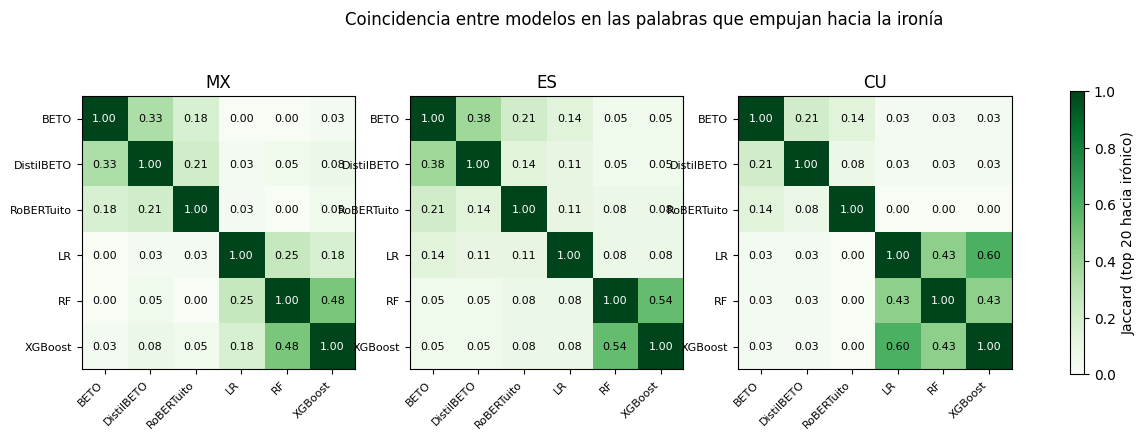

,variante,modelo_a,modelo_b,jaccard
0,mx,BETO,DistilBETO,0.333
1,mx,BETO,RoBERTuito,0.176
2,mx,BETO,LR,0.000
3,mx,BETO,RF,0.000
4,mx,BETO,XGBoost,0.026
5,mx,DistilBETO,RoBERTuito,0.212
6,mx,DistilBETO,LR,0.026
7,mx,DistilBETO,RF,0.053
8,mx,DistilBETO,XGBoost,0.081
9,mx,RoBERTuito,LR,0.026


In [4]:
def conjunto(variante, modelo):
    g = GLOBAL[(GLOBAL["variante"] == variante) & (GLOBAL["modelo"] == modelo) & (GLOBAL["shap_medio"] > 0)]
    return set(g.nlargest(TOP_N, "shap_medio")["termino_norm"])


filas = []
fig, axes = plt.subplots(1, len(VARIANTES), figsize=(5.0 * len(VARIANTES), 4.6), squeeze=False)
for ax, variante in zip(axes[0], VARIANTES):
    M = np.full((len(MODELOS), len(MODELOS)), np.nan)
    for a, ma in enumerate(MODELOS):
        for b, mb in enumerate(MODELOS):
            A, B = conjunto(variante, ma), conjunto(variante, mb)
            if A and B:
                M[a, b] = len(A & B) / len(A | B)
                if a < b:
                    filas.append({"variante": variante, "modelo_a": ma, "modelo_b": mb, "jaccard": M[a, b],
                                  "comunes": ", ".join(sorted(A & B))})
    im = ax.imshow(M, cmap="Greens", vmin=0, vmax=1)
    for a in range(len(MODELOS)):
        for b in range(len(MODELOS)):
            if not np.isnan(M[a, b]):
                ax.text(b, a, f"{M[a, b]:.2f}", ha="center", va="center", fontsize=8,
                        color="white" if M[a, b] > 0.6 else "black")
    ax.set_xticks(range(len(MODELOS)), MODELOS, rotation=45, ha="right", fontsize=8)
    ax.set_yticks(range(len(MODELOS)), MODELOS, fontsize=8)
    ax.set_title(variante.upper())
fig.colorbar(im, ax=axes[0].tolist(), shrink=0.8, label=f"Jaccard (top {TOP_N} hacia irónico)")
fig.suptitle("Coincidencia entre modelos en las palabras que empujan hacia la ironía", fontsize=12)
fig.savefig(OUT_DIR / "coincidencia_jaccard.png", dpi=200, bbox_inches="tight")
fig.savefig(OUT_DIR / "coincidencia_jaccard.pdf", bbox_inches="tight")
display(fig)
plt.close(fig)
JACCARD = pd.DataFrame(filas)
JACCARD.to_csv(OUT_DIR / "coincidencia_jaccard.csv", index=False)
display(JACCARD.drop(columns="comunes").round(3))

## 3. ¿Qué tiene de distinto cada variante?

Para RoBERTuito (modelo principal) y LR (ML más interpretable) se comparan las `TOP_N` palabras más "irónicas" de MX, ES y CU: cuáles comparten las tres variantes y cuáles aparecen solo en una. Archivo: `palabras_por_variante.csv`.

In [5]:
filas = []
for modelo in [MODELO_PRINCIPAL, ML_PRINCIPAL]:
    if modelo not in MODELOS:
        continue
    conj = {v: conjunto(v, modelo) for v in VARIANTES}
    comunes = set.intersection(*conj.values()) if all(conj.values()) else set()
    print(f"\n{modelo} — compartidas por MX, ES y CU ({len(comunes)}): {', '.join(sorted(comunes)) or '—'}")
    for v in VARIANTES:
        propias = conj[v] - set().union(*(conj[o] for o in VARIANTES if o != v))
        print(f"{modelo} — solo en {v.upper()} ({len(propias)}): {', '.join(sorted(propias)) or '—'}")
        for termino in conj[v]:
            filas.append({"modelo": modelo, "variante": v, "termino": termino,
                          "compartida_por_las_3": termino in comunes, "solo_en_esta_variante": termino in propias})
pd.DataFrame(filas).to_csv(OUT_DIR / "palabras_por_variante.csv", index=False)


RoBERTuito — compartidas por MX, ES y CU (0): —
RoBERTuito — solo en MX (13): 4t, amlo, emoji, era, frente, hashtagg, jjaja, mi, ojos, persona, presidente, senora, van
RoBERTuito — solo en ES (14): calidad, despues, franco, ha, hay, he, libro, panales, para, pedro, puede, relator, tierra, yo
RoBERTuito — solo en CU (17): aceite, bien, cosa, cubano, eso, esos, estamos, favor, fin, jaja, manzanas, paquete, precio, prueba, puerco, que, salario

LR — compartidas por MX, ES y CU (1): ir
LR — solo en MX (18): 4t, 4ta, cara_pensativa, cara_revolviendose_de_la_risa, cree, cuarta, cuidar, cuidar nietos, despues, falta, hacen, jajajajaja, mafia, mal, nunca, pueblo, sigue, transformacion
LR — solo en ES (18): cambio, cara_llorando_de_risar, gracias, hombre, libro, llevar, manual, mirar, panal, pedro, poder ser, relator, saber, salvaje, si, tener, user haber, yoconalbert
LR — solo en CU (19): cuc, demis, etecs, jajaj, jajajaj, lleg, lun, manzan, maravill, mes, mir, pa, parec, pie, quer, segur, va

## 4. Rasgos del tuit: risas, emojis, menciones, hashtags y puntuación

Los modelos de ML usan 9 rasgos lingüísticos explícitos (`ml_shap_rasgos.csv`). Para los Transformers se agrupan sus tokens en categorías equivalentes con expresiones regulares (por ejemplo, `jaja…` → risas; los emojis aparecen como texto tras el preprocesamiento de `pysentimiento`) y se promedia su contribución SHAP **en los tuits donde aparecen**. Un valor positivo indica que el rasgo empuja hacia *irónico*. Archivo: `rasgos_por_modelo.csv`.

In [6]:
CATEGORIAS = {
    "risas": r"^(?:ja|je|ji|jo|ha|he|xd|lol|jsj)+[aeijos]*$",
    "emojis": r"emoji",
    "menciones": r"^@?(?:usuario|user)$",
    "hashtags": r"^#|^hashtag$",
    "exclamaciones": r"^[!¡]+$",
    "interrogaciones": r"^[?¿]+$",
    "puntos suspensivos": r"^\.{2,}$|^…$",
    "comillas": r"^[\"“”«»']+$",
    "negaciones": r"^(?:no|nunca|jamas|jamás|tampoco|ni)$",
}
filas = []
if not TOKENS.empty:
    tok = TOKENS.copy()
    tok["t"] = tok["token"].astype(str).str.replace("Ġ", " ").str.replace("##", "").str.strip().str.lower().str.strip(".,;:")
    for categoria, patron in CATEGORIAS.items():
        m = tok[tok["t"].str.contains(patron, regex=True, na=False)]
        for (variante, modelo), g in m.groupby(["variante", "modelo"]):
            por_tuit = g.groupby("ID")["shap"].sum()  # contribución total del rasgo en cada tuit
            filas.append({"variante": variante, "modelo": modelo, "rasgo": categoria,
                          "n_textos": int(por_tuit.size), "shap_medio": float(por_tuit.mean())})
ruta_rasgos_ml = ML_DIR / "ml_shap_rasgos.csv"
if ruta_rasgos_ml.exists():
    r = pd.read_csv(ruta_rasgos_ml)
    filas += r[[c for c in ["variante", "modelo", "rasgo", "n_textos", "shap_medio"] if c in r.columns]].to_dict("records")
RASGOS = pd.DataFrame(filas)
RASGOS.to_csv(OUT_DIR / "rasgos_por_modelo.csv", index=False)
if not RASGOS.empty:
    tabla = RASGOS.pivot_table(index="rasgo", columns=["modelo", "variante"], values="shap_medio")
    signo = tabla.apply(lambda col: col.map(
        lambda x: "" if pd.isna(x) else ("+ irónico" if x > 0 else ("− no irónico" if x < 0 else "0"))))
    print("Dirección del efecto de cada rasgo (modelo × variante):")
    display(signo)
    display(tabla.round(4))

Dirección del efecto de cada rasgo (modelo × variante):


modelo                      BETO                                DistilBETO  \
variante                      cu            es            mx            cu   
rasgo                                                                        
alargamientos                                                                
comillas                          − no irónico                               
emojis                               + irónico     + irónico                 
exclamaciones          + irónico  − no irónico     + irónico                 
hashtags                          − no irónico  − no irónico     + irónico   
interrogaciones        + irónico  − no irónico     + irónico     + irónico   
mayúsculas                                                                   
menciones                         − no irónico  − no irónico                 
negaciones          − no irónico  − no irónico  − no irónico  − no irónico   
puntos suspensivos                                                           
risas                  + irónico     + irónico     + irónico     + irónico   

modelo                                                    LR                \
variante                      es            mx            cu            es   
rasgo                                                                        
alargamientos                                      + irónico  − no irónico   
comillas            − no irónico     + irónico     + irónico  − no irónico   
emojis              − no irónico     + irónico                   + irónico   
exclamaciones       − no irónico     + irónico     + irónico     + irónico   
hashtags            − no irónico  − no irónico                               
interrogaciones     − no irónico     + irónico     + irónico     + irónico   
mayúsculas                                         + irónico  − no irónico   
menciones           − no irónico  − no irónico                               
negaciones          − no irónico  − no irónico  − no irónico  − no irónico   
puntos suspensivos                                 + irónico     + irónico   
risas                  + irónico     + irónico     + irónico                 

modelo                                      RF                              \
variante                      mx            cu            es            mx   
rasgo                                                                        
alargamientos          + irónico     + irónico     + irónico     + irónico   
comillas               + irónico     + irónico  − no irónico     + irónico   
emojis                 + irónico                   + irónico     + irónico   
exclamaciones          + irónico     + irónico     + irónico     + irónico   
hashtags                                                                     
interrogaciones        + irónico     + irónico     + irónico     + irónico   
mayúsculas          − no irónico     + irónico  − no irónico  − no irónico   
menciones                                                                    
negaciones          − no irónico  − no irónico  − no irónico  − no irónico   
puntos suspensivos     + irónico     + irónico     + irónico     + irónico   
risas                  + irónico     + irónico                   + irónico   

modelo                RoBERTuito                                   XGBoost  \
variante                      cu            es            mx            cu   
rasgo                                                                        
alargamientos                                                    + irónico   
comillas                             + irónico  − no irónico     + irónico   
emojis                               + irónico     + irónico                 
exclamaciones          + irónico  − no irónico     + irónico     + irónico   
hashtags            − no irónico                                             
interrogaciones     − no irónico     + irónico     + irónico     + irónico   
mayúsculas         

modelo                BETO                 DistilBETO                      LR  \
variante                cu      es      mx         cu      es      mx      cu   
rasgo                                                                           
alargamientos          NaN     NaN     NaN        NaN     NaN     NaN  0.8103   
comillas               NaN -0.0001     NaN        NaN -0.0650  0.0555  3.0742   
emojis                 NaN  0.0458  0.0538        NaN -0.0266  0.1254     NaN   
exclamaciones       0.1505 -0.0435  0.1106        NaN -0.0035  0.0454  0.2431   
hashtags               NaN -0.0470 -0.0530     0.0014 -0.0779 -0.0370     NaN   
interrogaciones     0.0408 -0.0122  0.0144     0.0835 -0.0159  0.0186  0.0447   
mayúsculas             NaN     NaN     NaN        NaN     NaN     NaN  0.0367   
menciones              NaN -0.0222 -0.1565        NaN -0.0328 -0.1322     NaN   
negaciones         -0.0360 -0.0223 -0.0065    -0.0293 -0.0263 -0.0173 -0.0940   
puntos suspensivos     NaN     NaN     NaN        NaN     NaN     NaN  0.9019   
risas               0.0614  0.0050  0.0418     0.1692  0.0016  0.0389  0.9790   

modelo                                  RF                 RoBERTuito          \
variante                es      mx      cu      es      mx         cu      es   
rasgo                                                                           
alargamientos      -0.1533  0.1203  0.0299  0.0220  0.0293        NaN     NaN   
comillas           -0.3533  0.3421  0.0532 -0.0431  0.0127        NaN  0.0021   
emojis              0.1178  0.2776     NaN  0.0078  0.0363        NaN  0.0187   
exclamaciones       0.2223  0.1645  0.0176  0.0064  0.0122     0.0035 -0.0207   
hashtags               NaN     NaN     NaN     NaN     NaN    -0.0117     NaN   
interrogaciones     0.0683  0.0347  0.0043  0.0180  0.0018    -0.0263  0.0144   
mayúsculas         -0.1928 -0.1455  0.0106 -0.0176 -0.0034        NaN     NaN   
menciones              NaN     NaN     NaN     NaN     NaN        NaN -0.0207   
negaciones         -0.2746 -0.2026 -0.0006 -0.0230 -0.0064    -0.0319 -0.0770   
puntos suspensivos  0.4493  0.2796  0.0168  0.0100  0.0101        NaN     NaN   
risas                  NaN  0.5421  0.0064     NaN  0.0024     0.0370  0.0202   

modelo                     XGBoost                  
variante                mx      cu      es      mx  
rasgo                                               
alargamientos          NaN  0.7254  0.1358  0.4312  
comillas           -0.0109  1.1057 -0.5461  0.4144  
emojis              0.0338     NaN -0.0334  0.6167  
exclamaciones       0.0004  0.3971  0.1571  0.2089  
hashtags               NaN     NaN     NaN     NaN  
interrogaciones     0.0476  0.0195  0.0875  0.1349  
mayúsculas             NaN  0.3196 -0.1331 -0.1262  
menciones          -0.0687     NaN     NaN     NaN  
negaciones         -0.0380 -0.0363 -0.1722 -0.1331  
puntos suspensivos     NaN  0.0000  0.1111  0.1343  
risas               0.0499  0.0350     NaN  0.0469

## 5. Cómo usar estos resultados en el artículo

- **Figuras principales:** `robertuito_shap_global.png` (palabras por variante) y `ml_shap_palabras.png` (LR, RF y XGBoost); en el anexo, las de BETO y DistilBETO y `coincidencia_jaccard.png`.
- **Ejemplos locales:** `robertuito_shap_ejemplos.png` y los HTML de `shap_html/` (un acierto, un falso positivo y un falso negativo por variante), junto con `errores_consistentes_robertuito.csv` del notebook 06.
- **Redacción:** describir qué palabras y rasgos empujan hacia la ironía en cada variante, qué comparte Cuba con MX y ES y qué no, y si los modelos coinciden (Jaccard). SHAP explica el comportamiento del modelo; no prueba causalidad lingüística ni cambia los resultados.